# 01 — Superdense coding: teori, diagram, dan pengukuran

**Quantum Chat 0.1.0 · research preview · MIT · Python 3.12.**

Notebook ini menurunkan alur dua bit → satu qubit yang dikirim setelah satu
pasangan Bell dibagikan, lalu memeriksa empat simbol memakai engine proyek.
Ini simulasi lokal, bukan pengiriman qubit fisik atau komunikasi instan.
Jalankan seluruh cell berurutan pada environment repository.


In [1]:
from pathlib import Path
import sys, platform, importlib.metadata as metadata
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'pyproject.toml').exists() and (p/'densechat').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cirq, qsimcirq
from IPython.display import display
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
from scripts.notebook_support import style, save, COLORS
style()
SEED = 20261106
print('Python:', platform.python_version(), '| seed:', SEED)
print({name: metadata.version(name) for name in ['cirq-core', 'qsimcirq', 'numpy', 'matplotlib']})


Python: 3.12.16 | seed: 20261106
{'cirq-core': '1.7.0', 'qsimcirq': '0.22.1', 'numpy': '2.5.4', 'matplotlib': '3.11.2'}


## 1. Konvensi dan prasyarat

Urutan basis adalah $A,B$: $|00\rangle,|01\rangle,|10\rangle,|11\rangle$.
Pengirim memegang A, penerima memiliki B setelah distribusi awal. Pasangan Bell:

$$|\Phi^+\rangle=\mathrm{CNOT}_{A\to B}(H_A\otimes I)|00\rangle
=\frac{|00\rangle+|11\rangle}{\sqrt 2}.$$

Bit pesan ditulis $z,x$. Gate diterapkan **Z dahulu lalu X** pada A, sehingga
operator total $X^xZ^z$. Setelah A tiba, receiver melakukan CNOT lalu H(A):

$$(H_A\otimes I)\,\mathrm{CNOT}_{A\to B}
(X_A^xZ_A^z\otimes I)|\Phi^+\rangle=e^{i\theta}|zx\rangle.$$

Fase global $e^{i\theta}$ tidak mengubah probabilitas pengukuran.


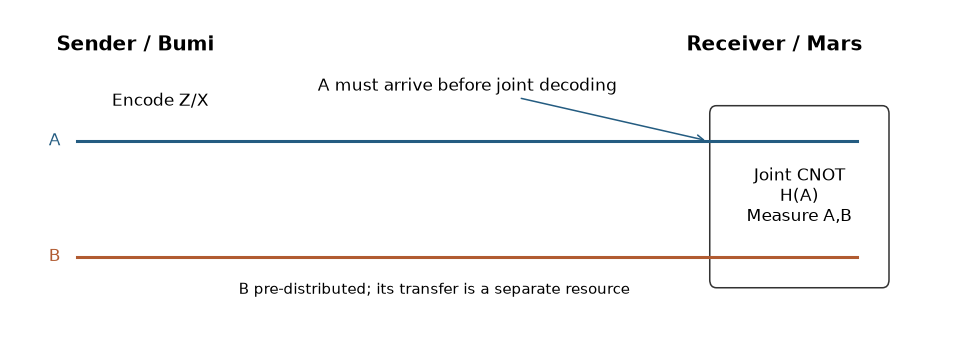

In [2]:
from scripts.notebook_support import ownership
fig = ownership()
save(fig, 'superdense_ownership')
display(fig); plt.close(fig)


## 2. Circuit yang benar-benar digunakan aplikasi

Kode berikut mengimpor fungsi engine aktif. Gate dan hasil bukan diagram
dekoratif yang terpisah dari implementasi. Contoh z=x=1 dapat memiliki tanda
minus global pada akhir circuit tanpa mengubah hasil `11`.


0: ───H───@───Z───X───@───H───M('received')───
          │           │       │
1: ───────X───────────X───────M───────────────


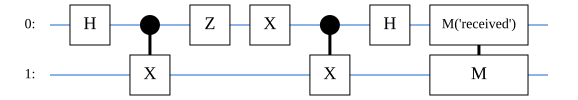

In [3]:
from densechat.quantum import encode_pair, transfer_qubit_a, joint_decode
from cirq.contrib.svg import SVGCircuit
A, B = cirq.LineQubit.range(2)
circuit = joint_decode(transfer_qubit_a(encode_pair(1, 1)))
print(circuit)
display(SVGCircuit(circuit))


## 3. Verifikasi semua simbol

Setiap shot mempersiapkan Bell pair baru. Kami memakai `repetitions=1` per
run, menghindari interpretasi urutan keluaran sampler terminal multi-shot
sebagai urutan pengukuran lokal. Tabel di bawah dihitung oleh qsimcirq.


In [4]:
symbol_rows = []
for z in (0, 1):
    for x in (0, 1):
        ideal = joint_decode(transfer_qubit_a(encode_pair(z, x)))
        simulator = qsimcirq.QSimSimulator(seed=SEED + 2*z + x, qsim_options={'t': 1})
        shots = [''.join(map(str, map(int, simulator.run(ideal, repetitions=1).measurements['received'][0]))) for _ in range(32)]
        expected = f'{z}{x}'
        assert all(result == expected for result in shots)
        symbol_rows.append({'input z,x': expected, 'shots': len(shots), 'correct': sum(s == expected for s in shots)})
display(pd.DataFrame(symbol_rows))


,"input z,x",shots,correct
0,00,32,32
1,01,32,32
2,10,32,32
3,11,32,32


## 4. Mengapa B sendiri tidak membaca pilihan pengirim

Untuk semua empat encoding, $\rho_B=\operatorname{Tr}_A(|\psi\rangle\langle\psi|)=I/2$.
Karena itu $P(B=0)=P(B=1)=1/2$. Perubahan tanda relatif dapat mengubah
Bell state, tetapi tidak mengubah marginal B. Joint decoding membutuhkan A.
Perhitungan global berikut hanya merupakan **observer diagnostik**, bukan
data yang diberikan ke endpoint penerima chat.


In [5]:
states, marginal_rows = [], []
for z in (0, 1):
    for x in (0, 1):
        prefix = cirq.Circuit(encode_pair(z, x).circuit)
        vector = qsimcirq.QSimSimulator(seed=SEED).simulate(prefix, qubit_order=[A, B]).final_state_vector.astype(complex)
        rho = np.outer(vector, vector.conj())
        rho_b = np.trace(rho.reshape(2,2,2,2), axis1=0, axis2=2)
        np.testing.assert_allclose(rho_b, np.eye(2)/2, atol=1e-6)
        states.append((f'{z}{x}', rho))
        marginal_rows.append({'input': f'{z}{x}', 'state': cirq.dirac_notation(vector, decimals=3),
                              'P(B=0)': rho_b[0,0].real, 'P(B=1)': rho_b[1,1].real})
display(pd.DataFrame(marginal_rows))


,input,state,P(B=0),P(B=1)
0,00,0.707|00⟩ + 0.707|11⟩,0.5,0.5
1,01,0.707|01⟩ + 0.707|10⟩,0.5,0.5
2,10,0.707|00⟩ - 0.707|11⟩,0.5,0.5
3,11,-0.707|01⟩ + 0.707|10⟩,0.5,0.5


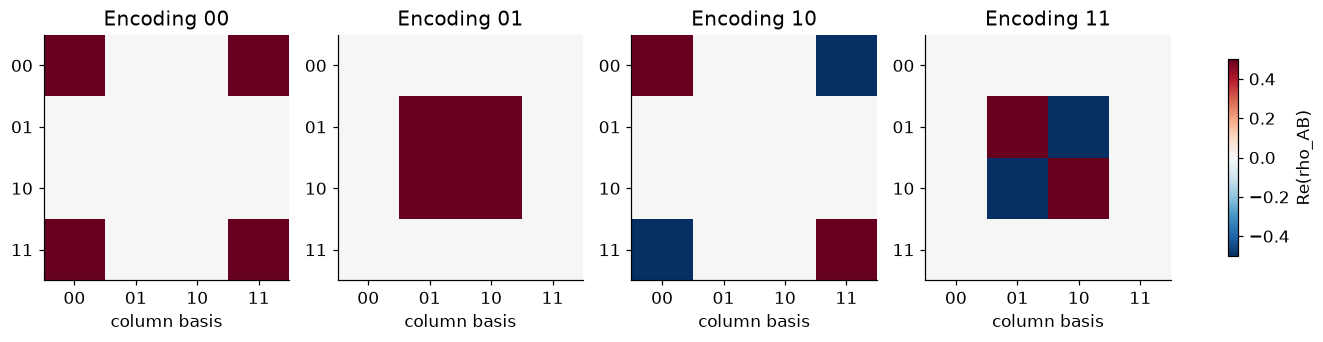

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3), constrained_layout=True)
for ax, (bits, rho) in zip(axes, states):
    image = ax.imshow(rho.real, vmin=-.5, vmax=.5, cmap='RdBu_r')
    ax.set(title=f'Encoding {bits}', xticks=range(4), yticks=range(4),
           xticklabels=['00','01','10','11'], yticklabels=['00','01','10','11'])
    ax.set_xlabel('column basis')
fig.colorbar(image, ax=axes, label='Re(rho_AB)', shrink=.8)
save(fig, 'bell_density_matrices')
display(fig); plt.close(fig)


## 5. Interpretasi dan batas

Assertion empat simbol memeriksa mapping bit, sedangkan reduced-state check
memeriksa marginal ideal. Ini bukan pengujian hardware atau penemuan kanal
tanpa transfer. Satu pasangan memiliki dua qubit: biaya awal distribusi B
dan biaya pengiriman A perlu dinyatakan terpisah. Persamaan $I/2$ menjelaskan
mengapa lebih banyak sampel lokal B tidak menyediakan encoding pengirim.

Berikutnya: [notebook 02](02_quantum_chat_protocol.ipynb) menghubungkan simbol
dua bit menjadi frame teks, checksum, ACK dan biaya protokol.


## Referensi primer dan cara mengutip

1. C. H. Bennett & S. J. Wiesner (1992), *Communication via one- and two-particle
   operators on Einstein-Podolsky-Rosen states*, Physical Review Letters 69, 2881.
   [DOI: 10.1103/PhysRevLett.69.2881](https://doi.org/10.1103/PhysRevLett.69.2881).
2. [IBM Quantum Learning — superdense coding](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/entanglement-in-action/superdense-coding).
3. [IBM Quantum Learning — reduced states](https://quantum.cloud.ibm.com/learning/en/courses/general-formulation-of-quantum-information/density-matrices/multiple-systems).
4. [Google Quantum AI — qsimcirq](https://quantumai.google/qsim/tutorials/qsimcirq),
   [DepolarizingChannel](https://quantumai.google/reference/python/cirq/DepolarizingChannel).

BibTeX ada pada [docs/references.bib](../docs/references.bib), metadata software
pada [CITATION.cff](../CITATION.cff). Tidak ada DOI software atau klaim peer-review.
Notebook ini merupakan penjelasan dan verifikasi numerik protokol yang sudah ada.
